# P6 — Morfologi dan Analisis Bercak SIMUTEH

Notebook ini mengikuti petunjuk praktikum P5-P6 SIMUTEH.

## Bagian 3 — Operasi morfologi pada citra biner

In [1]:

from pathlib import Path
import json
import sys
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
from bercak import analisis_daun, PARAM_BERCAK, simpan_param

def tepi_canny(gray, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        gray = cv2.GaussianBlur(gray, (0, 0), sigma)
    return cv2.Canny(gray, lo, hi)

PARAM = json.loads((root / "hasil" / "param_praproses.json").read_text(encoding="utf-8"))
label = pd.read_csv(root / "data" / "sintetis" / "label.csv")
hasil_dir = root / "hasil"
hasil_dir.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 30)

def muat(nama):
    img = baca(str(root / "data" / "sintetis" / "citra" / nama))
    md = cv2.imread(str(root / "data" / "sintetis" / "mask_daun" / nama), 0)
    mb = cv2.imread(str(root / "data" / "sintetis" / "mask_bercak" / nama), 0)
    if md is None or mb is None:
        raise FileNotFoundError(f"Mask tidak lengkap untuk {nama}")
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)
acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
print("Root:", root.name)
print("Jumlah citra:", len(label))


Root: Simuteh-1063
Jumlah citra: 60


### Langkah 3.1 — Lembar hitung manual

In [2]:
B = np.array([
    [0,0,0,0,0,0,0,0,0], [0,1,1,1,0,0,0,0,0], [0,1,0,1,0,0,0,1,0],
    [0,1,1,1,0,0,0,0,0], [0,0,0,0,1,0,0,0,0], [0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0], [0,1,1,1,1,1,1,0,0], [0,0,0,0,0,0,0,0,0]], dtype=np.uint8) * 255
se3 = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
def morf(op, m):
    return op(m, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
def cetak(nama, m):
    print(nama); print((m > 0).astype(int))
print("Komponen 4:", cv2.connectedComponents((B > 0).astype(np.uint8), connectivity=4)[0] - 1)
print("Komponen 8:", cv2.connectedComponents((B > 0).astype(np.uint8), connectivity=8)[0] - 1)
cetak("Erosi", morf(cv2.erode, B))
cetak("Opening", cv2.morphologyEx(B, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0))
cetak("Closing", cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0))
tertutup = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
cetak("Closing lalu opening", cv2.morphologyEx(tertutup, cv2.MORPH_OPEN, se3,
                                               borderType=cv2.BORDER_CONSTANT, borderValue=0))


Komponen 4: 4
Komponen 8: 3
Erosi
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
Opening
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
Closing
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
Closing lalu opening
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


### Langkah 3.2–3.3 — Mask awal dan operasi

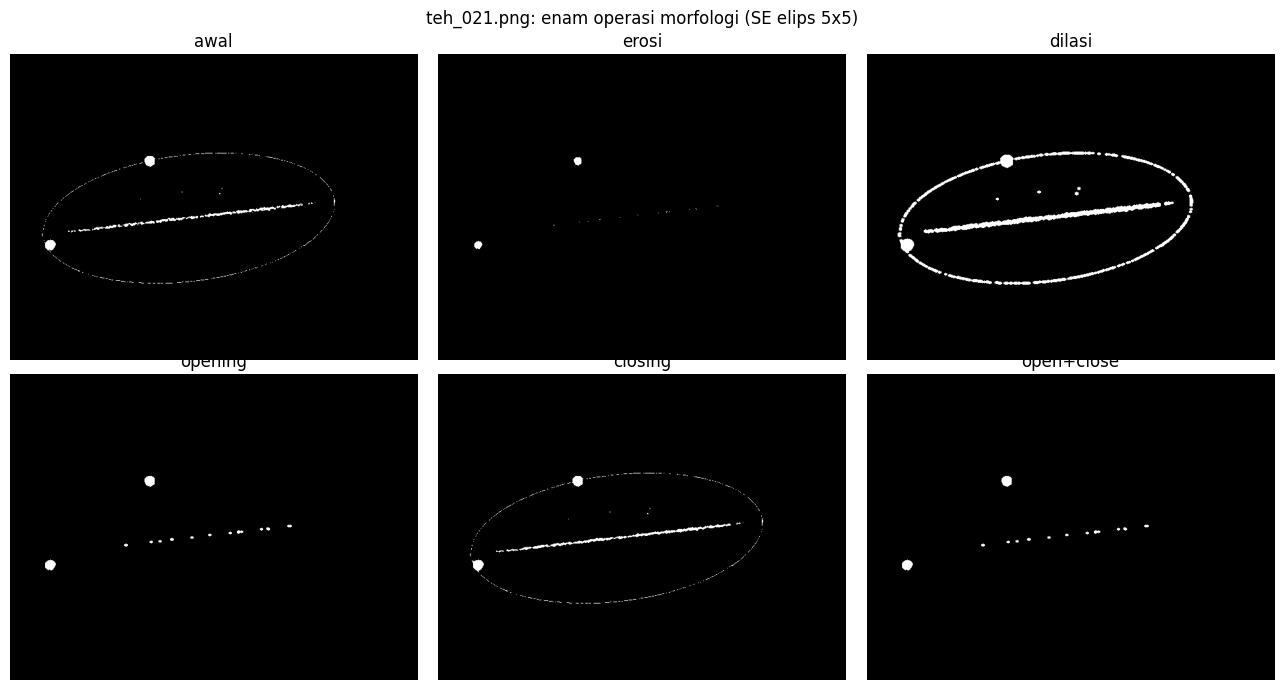

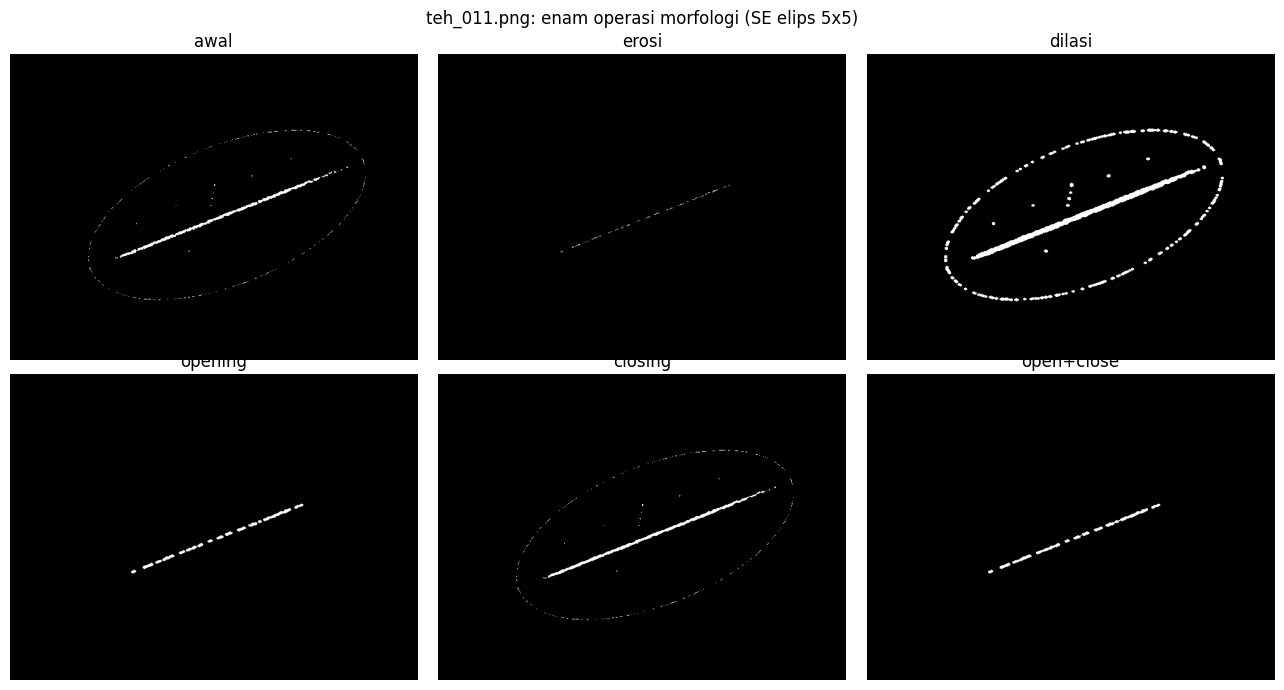

Tabel operasi morfologi:
      citra    operasi  komponen  piksel   IoU
teh_021.png       awal       213    2122 0.145
teh_021.png      erosi        15     261 0.419
teh_021.png     dilasi        32    7775 0.049
teh_021.png    opening        13     667 0.431
teh_021.png    closing       193    2254 0.141
teh_021.png open+close        13     667 0.431
teh_011.png       awal       169    1757 0.000
teh_011.png      erosi        45     120 0.000
teh_011.png     dilasi        72    6280 0.000
teh_011.png    opening        15     927 0.000
teh_011.png    closing       165    1854 0.000
teh_011.png open+close         9     961 0.000


In [3]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1


def SE(k, bentuk=cv2.MORPH_ELLIPSE):
    return cv2.getStructuringElement(bentuk, (k, k))


def operasi(b, se):
    return {"awal": b, "erosi": cv2.erode(b, se), "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
                                           cv2.MORPH_CLOSE, se)}


baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    citra, _, mb_i = muat(nama)
    pra_i = praproses(citra, PARAM)
    b0 = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2, k=4.0)
    hasil_operasi = operasi(b0, SE(5))
    for nama_op, m in hasil_operasi.items():
        baris.append([nama, nama_op, jumlah_komponen(m), int((m > 0).sum()), iou(m, mb_i)])
    fig, ax = plt.subplots(2, 3, figsize=(13, 7))
    for sumbu, (nama_op, m) in zip(ax.ravel(), hasil_operasi.items()):
        sumbu.imshow(m, cmap="gray")
        sumbu.set_title(nama_op)
        sumbu.axis("off")
    fig.suptitle(f"{nama}: enam operasi morfologi (SE elips 5x5)")
    fig.tight_layout()
    nomor = nama.removesuffix(".png")
    fig.savefig(hasil_dir / f"p6_operasi_{nomor}.png", dpi=150, bbox_inches="tight")
    plt.show()
operasi_df = pd.DataFrame(
    baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]
)
print("Tabel operasi morfologi:")
print(operasi_df.round(3).to_string(index=False))
operasi_df.to_csv(hasil_dir / "p6_operasi_morfologi.csv", index=False)

### Langkah 3.4–3.6 — Eksperimen SE dan gradien morfologi

                       galat_jumlah    IoU
bentuk  ukuran kelas                      
elips   3      berat          12.95  0.603
               ringan         10.65  0.222
               sehat          10.35    NaN
        5      berat           2.90  0.627
               ringan          2.85  0.334
               sehat           3.35    NaN
        7      berat           0.55  0.644
               ringan          0.75  0.437
               sehat           0.45    NaN
persegi 3      berat           7.10  0.608
               ringan          6.35  0.249
               sehat           5.30    NaN
        5      berat           1.55  0.635
               ringan          1.45  0.417
               sehat           1.60    NaN
        7      berat           0.65  0.617
               ringan          0.95  0.343
               sehat           0.00    NaN
silang  3      berat          12.95  0.603
               ringan         10.65  0.222
               sehat          10.35    NaN
        5  

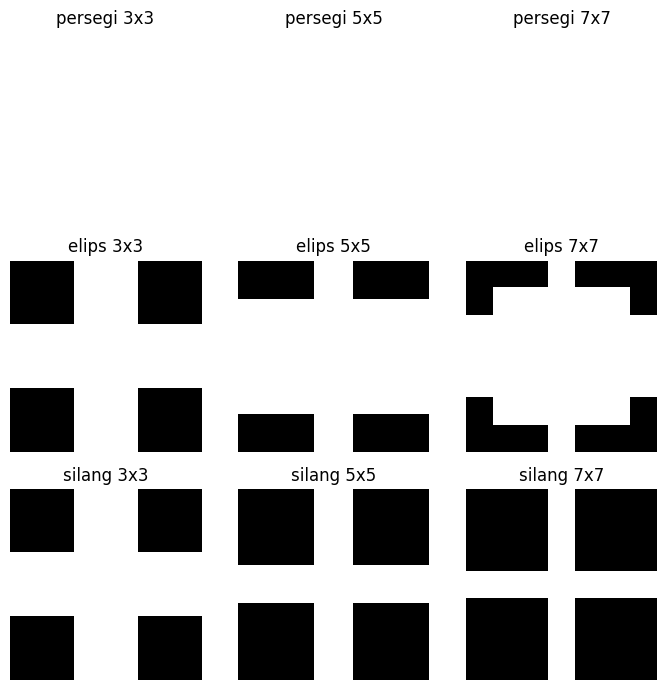

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.857     0.728
gelap                          0.983     0.687
kontras_rendah                 0.190     0.866
normal                         0.976     0.684
terang                         0.935     0.696


In [4]:

bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    b0 = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2)
    for k in [3, 4, 6]:
        b_k = bercak_awal(pra_i, mask_daun_awal(pra_i), kanal=2, k=k)
        for nama_b, kode_b in bentuk.items():
            for ukuran in [3, 5, 7]:
                se = SE(ukuran, kode_b)
                m = cv2.morphologyEx(cv2.morphologyEx(b_k, cv2.MORPH_OPEN, se),
                                     cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nama_b, ukuran,
                              abs(jumlah_komponen(m) - jumlah_komponen(mb_i)),
                              iou(m, mb_i) if mb_i.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks[eks.k == 4].groupby(["bentuk", "ukuran", "kelas"])[["galat_jumlah", "IoU"]].mean().round(3))
eks.to_csv(hasil_dir / "p6_eksperimen_se.csv", index=False)

t9 = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"])
urut_t9 = [(b_, u_) for b_ in ["persegi", "elips", "silang"] for u_ in [3, 5, 7]]
tabel9 = pd.DataFrame({
    "IoU berat": t9[("IoU", "berat")], "IoU ringan": t9[("IoU", "ringan")],
    "Galat jumlah berat": t9[("galat_jumlah", "berat")],
    "Galat jumlah ringan": t9[("galat_jumlah", "ringan")],
    "Galat jumlah sehat": t9[("galat_jumlah", "sehat")]}).loc[urut_t9].round(2)
print("\nTabel 9 (k = 4, format petunjuk):")
print(tabel9)
tabel9.to_csv(hasil_dir / "p6_tabel9_se_k4.csv")

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for i, (nama_b, kode_b) in enumerate(bentuk.items()):
    for j, ukuran in enumerate([3, 5, 7]):
        ax[i, j].imshow(SE(ukuran, kode_b), cmap="gray", vmin=0, vmax=1)
        ax[i, j].set_title(f"{nama_b} {ukuran}x{ukuran}"); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig(hasil_dir / "p6_panel_se.png", dpi=150); plt.show()

baris = []
for _, d in label.iterrows():
    citra, md_i, _ = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    grad = cv2.morphologyEx(mask_daun_awal(pra_i), cv2.MORPH_GRADIENT, SE(3))
    canny = tepi_canny(cv2.cvtColor(pra_i, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md_i)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
gradien = pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
print(gradien.groupby("kondisi").mean().round(3))
gradien.to_csv(hasil_dir / "p6_gradien_morfologi.csv", index=False)


## Bagian 4 — Komponen terhubung dan pengukuran bercak

Komponen konektivitas 4: 10
Komponen konektivitas 8: 10
   label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek      cx  \
0      1      117     22.39        38.38       1.00         1.09  434.89   
1      2      128     24.50        39.80       1.02         1.00  431.17   
2      3      217     41.54        53.46       0.95         1.00  255.97   
3      4      177     33.88        86.08       0.30         6.78  457.66   
4      5      196     37.52        97.74       0.26         8.20  417.35   
5      6      153     29.29        89.74       0.24         7.32  375.61   
6      7       78     14.93        30.49       1.05         1.12  519.00   
7      8      574    109.87       109.15       0.61         1.55  402.36   
8      9      823    157.53       370.23       0.08        27.13  276.60   
9     10      174     33.30        49.21       0.90         1.10  169.32   

       cy  
0  176.81  
1  208.86  
2  216.97  
3  225.29  
4  244.03  
5  263.21  
6  263.29  
7  284.02  

Tabel 11:
                  aturan  galat_jumlah_berat  galat_jumlah_ringan  galat_jumlah_sehat  daun_sehat_dengan_bercak_palsu
        luas + kebulatan                1.15                 1.40                1.45                              10
luas + kebulatan + rasio                0.80                 1.10                0.40                               3
              luas >= 20                1.70                 1.95                2.50                              10
            tanpa saring                2.90                 2.85                3.35                              10
Ringkasan komponen benar vs palsu (sesudah opening + closing, SE elips 5):
status                benar    palsu
luas_px     count    182.00   177.00
            min       17.00     1.00
            median   222.50    28.00
            max     1545.00  1568.00
kebulatan   count    182.00   177.00
            min        0.15     0.00
            median     0.95     0.86
            max        1.15  

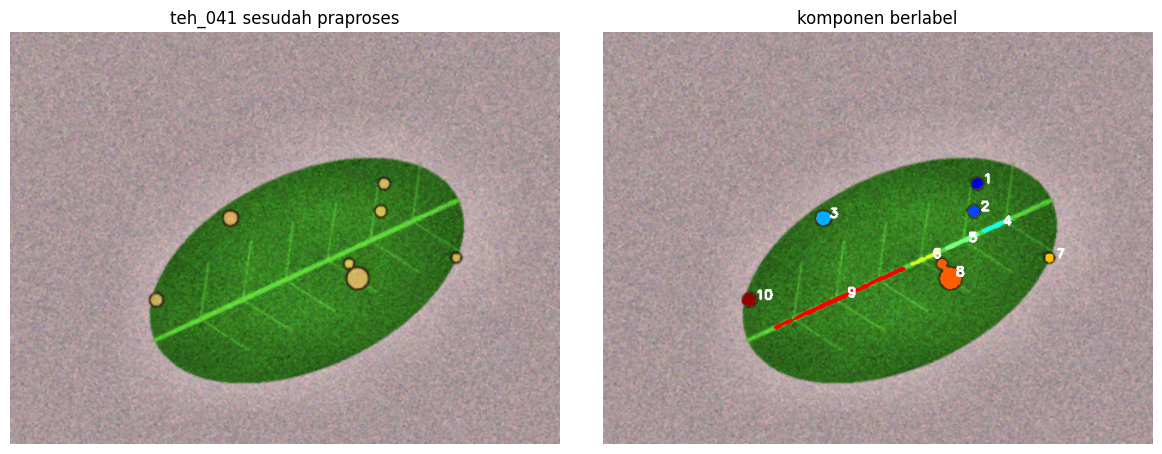

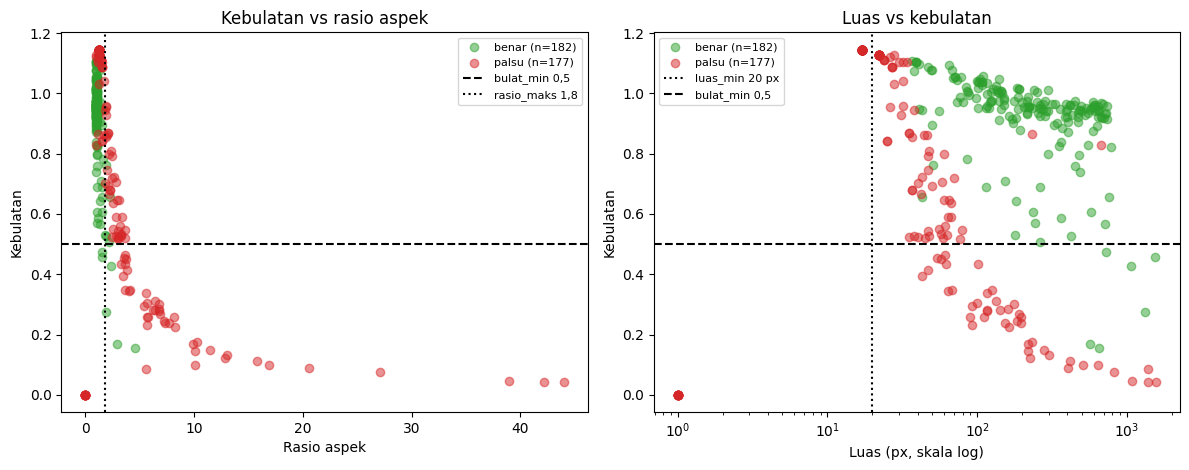

In [5]:
MM_PER_PX = 0.4375


def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        area = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * area / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, area, area * MM_PER_PX ** 2, keliling, kebulatan, rasio,
                      cen[i][0], cen[i][1]])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan",
             "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl


def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos


citra, md_i, mb_i = muat("teh_041.png")
pra_i = praproses(citra, PARAM)
b0 = bercak_awal(pra_i, mask_daun_awal(pra_i))
bersih = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
tabel_kom, lbl = ukur_komponen(bersih)
print("Komponen konektivitas 4:", jumlah_komponen(bersih, 4))
print("Komponen konektivitas 8:", jumlah_komponen(bersih, 8))
print(tabel_kom.round(2))
tabel_kom.to_csv(hasil_dir / "p6_ukuran_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(int(lbl.max()), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_i[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_i, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99),
          "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris, titik = [], []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    b = bercak_awal(pra_i, mask_daun_awal(pra_i))
    b = cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tabel_b, lbl_b = ukur_komponen(b)
    for _, r in tabel_b.iterrows():
        mask_i = lbl_b == int(r.label)
        overlap = float((mask_i & (mb_i > 0)).sum()) / max(int(mask_i.sum()), 1)
        titik.append([r.luas_px, r.kebulatan, r.rasio_aspek, "benar" if overlap > 0.5 else "palsu"])
    for nama_a, (a, bulat, rasio) in aturan.items():
        f, _ = saring(b, a, bulat, rasio)
        baris.append([d.kelas, nama_a, jumlah_komponen(f), jumlah_komponen(mb_i)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
ringkasan = uji.groupby(["aturan", "kelas"]).agg(galat_jumlah=("galat", "mean")).reset_index()
ringkasan = ringkasan.pivot(index="aturan", columns="kelas", values="galat_jumlah").reset_index()
ringkasan = ringkasan.rename(columns={
    "berat": "galat_jumlah_berat", "ringan": "galat_jumlah_ringan",
    "sehat": "galat_jumlah_sehat"
})
palsu = (uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0)
         .groupby("aturan")["palsu"].sum().rename("daun_sehat_dengan_bercak_palsu"))
ringkasan = ringkasan.set_index("aturan").join(palsu).reset_index()
print("Tabel 11:")
print(ringkasan.round(2).to_string(index=False))
ringkasan.to_csv(hasil_dir / "p6_penyaringan.csv", index=False)

titik_df = pd.DataFrame(titik, columns=["luas_px", "kebulatan", "rasio_aspek", "status"])
print("Ringkasan komponen benar vs palsu (sesudah opening + closing, SE elips 5):")
print(titik_df.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]]
      .agg(["count", "min", "median", "max"]).round(2).T)
lolos_semua = (titik_df.luas_px >= 20) & (titik_df.kebulatan >= 0.5) & (titik_df.rasio_aspek <= 1.8)
print("Komponen palsu yang tersaring     :", int((~lolos_semua & (titik_df.status == "palsu")).sum()),
      "dari", int((titik_df.status == "palsu").sum()))
print("Komponen benar yang ikut terbuang :", int((~lolos_semua & (titik_df.status == "benar")).sum()),
      "dari", int((titik_df.status == "benar").sum()))
warna_status = {"benar": "tab:green", "palsu": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for status, kelompok in titik_df.groupby("status"):
    ax[0].scatter(kelompok.rasio_aspek, kelompok.kebulatan, c=warna_status[status], alpha=0.5,
                  label=f"{status} (n={len(kelompok)})")
    ax[1].scatter(kelompok.luas_px, kelompok.kebulatan, c=warna_status[status], alpha=0.5,
                  label=f"{status} (n={len(kelompok)})")
ax[0].axhline(0.5, ls="--", c="k", label="bulat_min 0,5")
ax[0].axvline(1.8, ls=":", c="k", label="rasio_maks 1,8")
ax[0].set_xlabel("Rasio aspek"); ax[0].set_ylabel("Kebulatan")
ax[0].set_title("Kebulatan vs rasio aspek"); ax[0].legend(fontsize=8)
ax[1].axvline(20, ls=":", c="k", label="luas_min 20 px")
ax[1].axhline(0.5, ls="--", c="k", label="bulat_min 0,5")
ax[1].set_xscale("log"); ax[1].set_xlabel("Luas (px, skala log)"); ax[1].set_ylabel("Kebulatan")
ax[1].set_title("Luas vs kebulatan"); ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(hasil_dir / "p6_sebar_komponen.png", dpi=150)
plt.show()


## Bagian 5 — Integrasi analisis bercak SIMUTEH

Tabel 12 - akurasi per kondisi:
                akurasi  galat_persen
kondisi                              
bayangan          1.000         0.625
gelap             1.000         0.234
kontras_rendah    0.667         1.017
normal            0.750         0.580
terang            0.750         0.776
Galat absolut rerata persen: 0.646
Korelasi persen: 0.939
Akurasi kelas: 0.833
kelas_prediksi  Bercak Berat  Bercak Ringan  Sehat
kelas_acuan                                       
Bercak Berat              17              3      0
Bercak Ringan              0             15      5
Sehat                      0              2     18

10 dari 60 citra salah kelas


       nama        kondisi   kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  IoU_daun_awal  komp_biner_awal  komp_tersaring  komp_acuan  luas_prediksi_px  luas_acuan_px
teh_006.png         normal         Sehat  Bercak Ringan          0.00            0.125          0.997              212               3           0               102              0
teh_013.png         terang         Sehat  Bercak Ringan          0.00            0.103          0.997               36               3           0                66              0
teh_023.png         terang Bercak Ringan          Sehat          0.18            0.081          0.996               81               1           1                50            113
teh_024.png kontras_rendah Bercak Ringan          Sehat          0.25            0.000          0.518                0               0           1                 0            197
teh_031.png         normal Bercak Ringan          Sehat          0.24            0.048          0.99

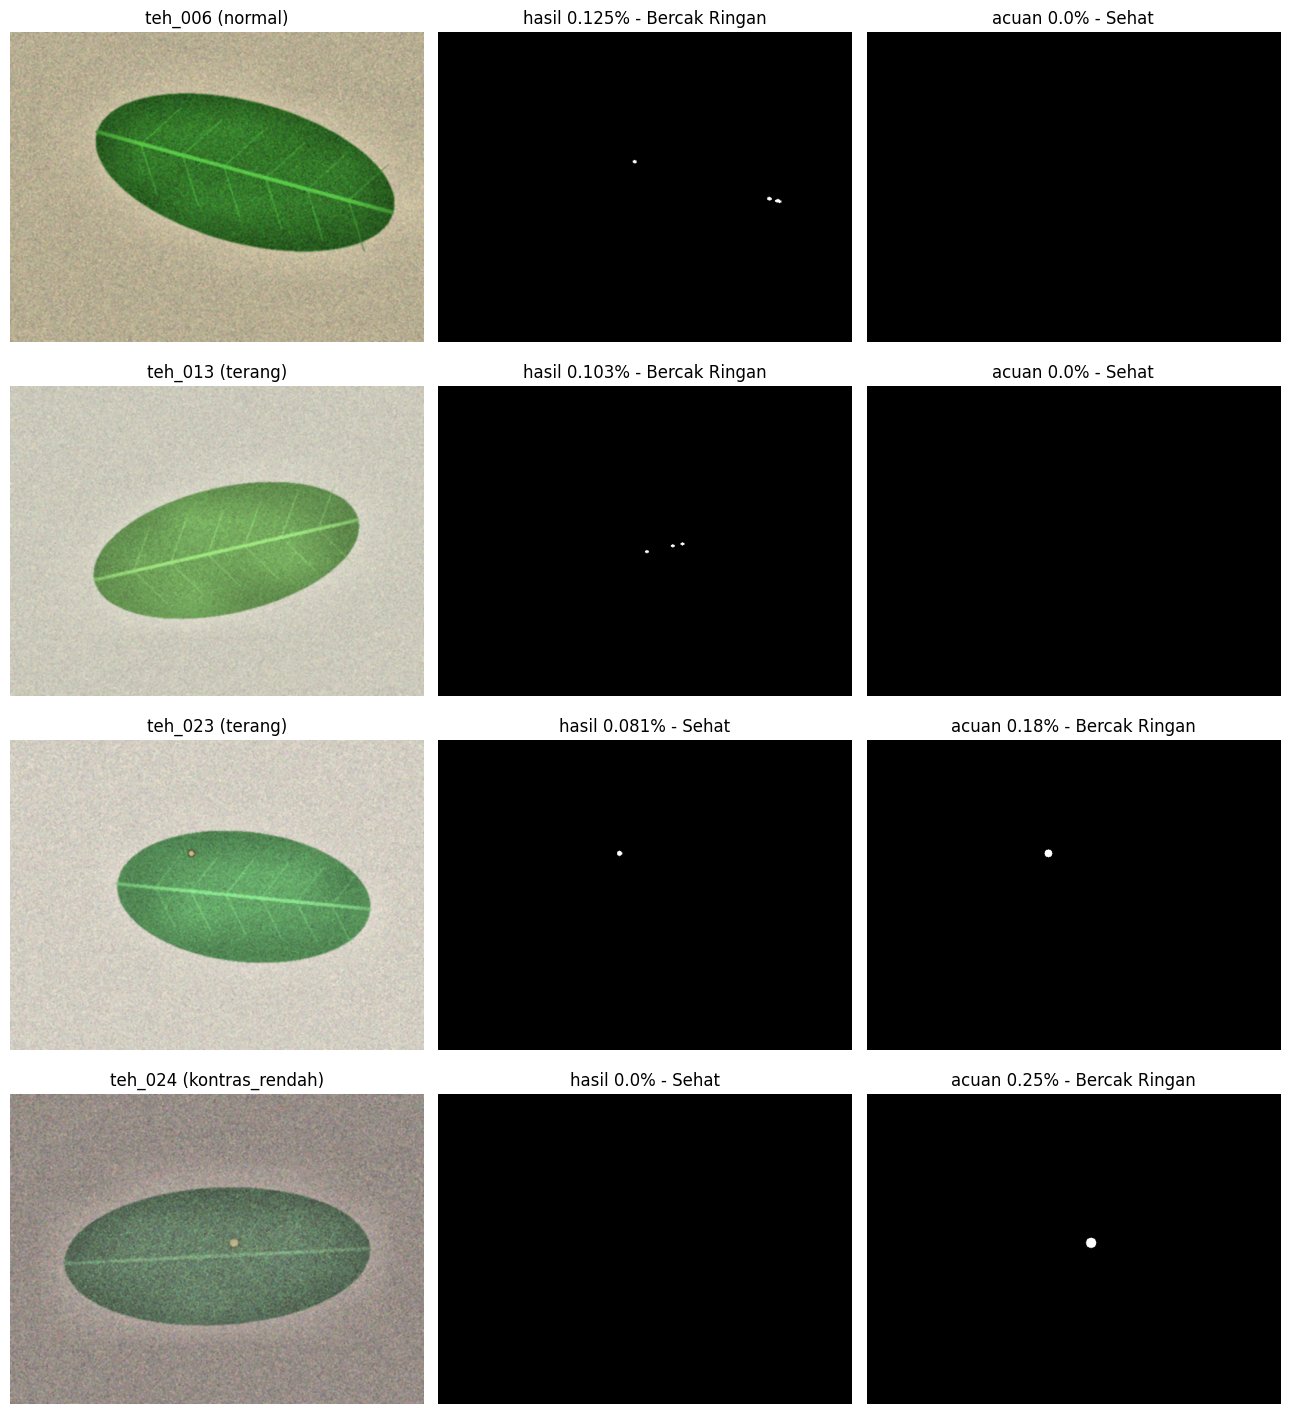

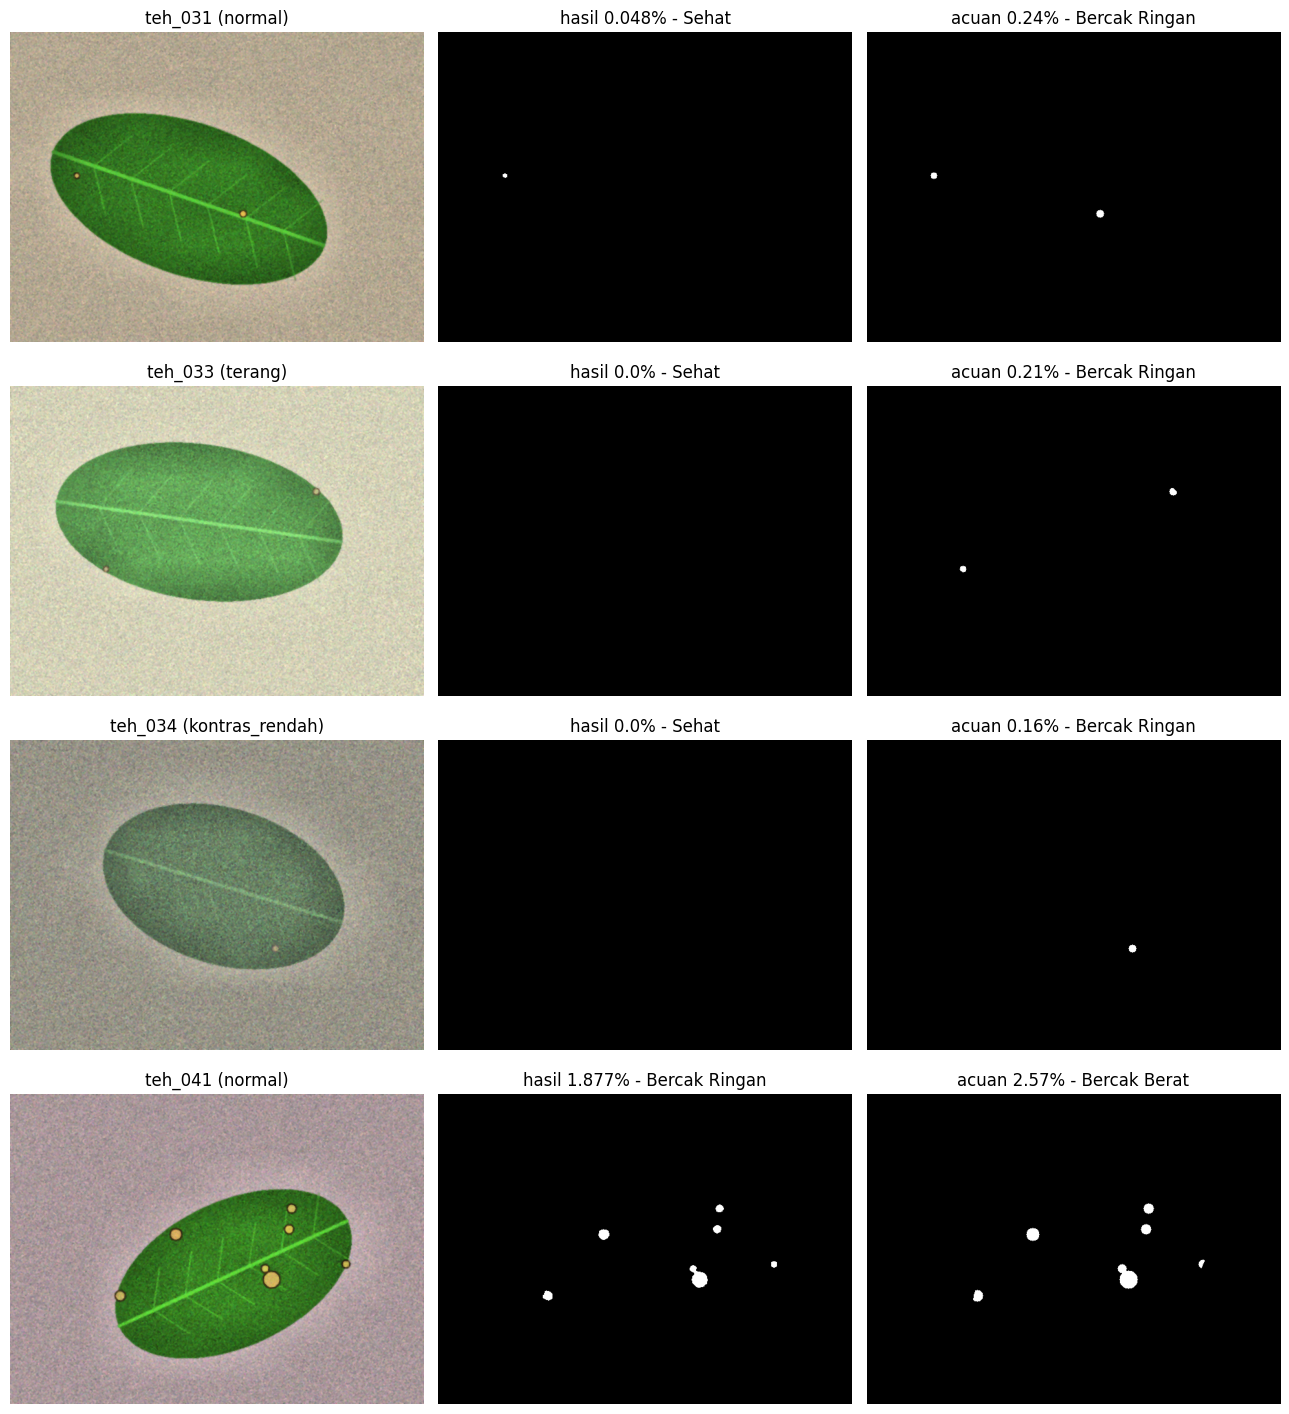

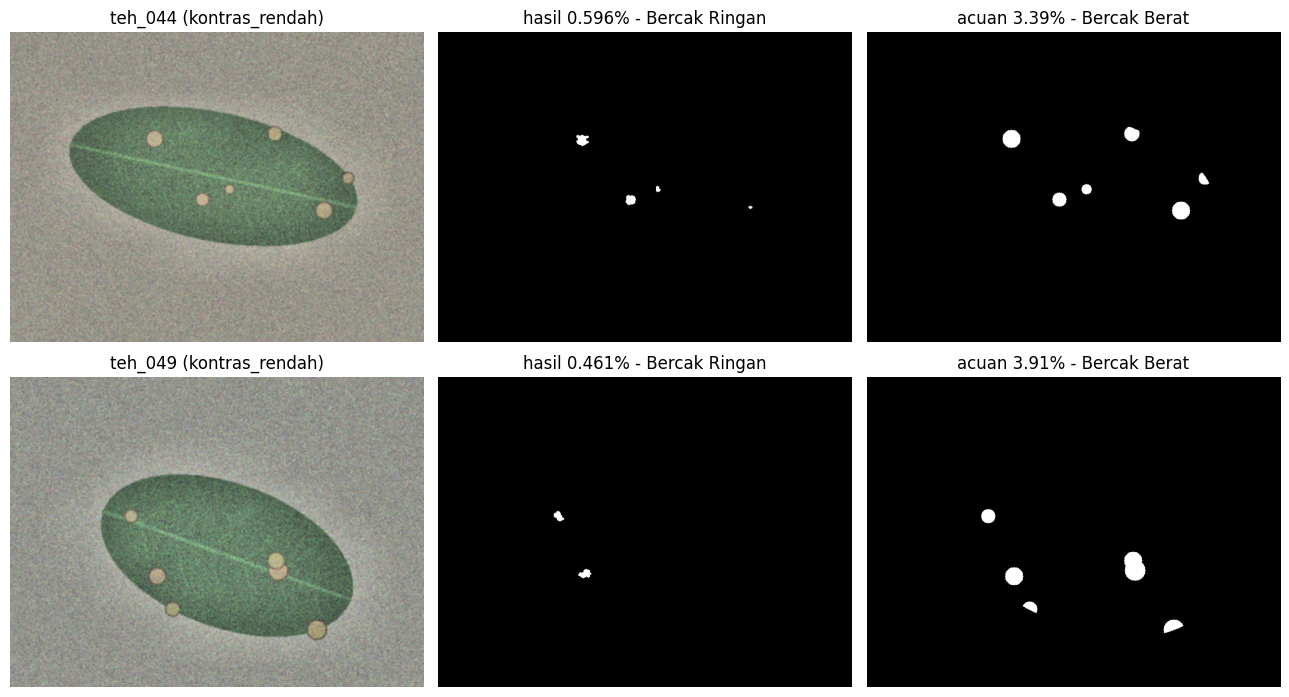

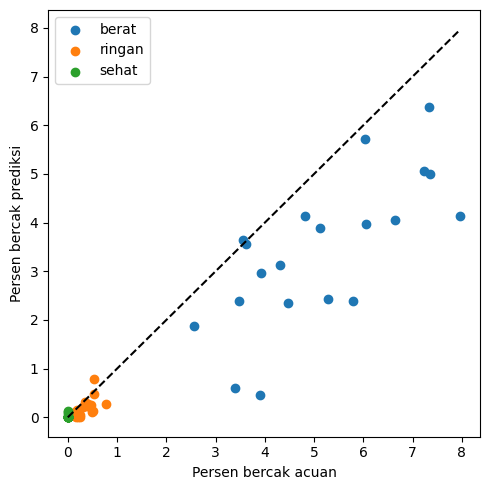

In [6]:
# Langkah 5.5 memakai satu implementasi bersama dari src/bercak.py.
simpan_param(PARAM_BERCAK, hasil_dir / "param_bercak.json")
baris = []
for _, d in label.iterrows():
    citra, _, mb_i = muat(d.nama_file)
    pra_i = praproses(citra, PARAM)
    pred = analisis_daun(pra_i)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak,
                  pred["persen_bercak"], jumlah_komponen(mb_i), pred["jumlah_bercak"],
                  pred["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan",
                                  "persen_prediksi", "jumlah_acuan", "jumlah_prediksi",
                                  "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev["galat_persen"] = (ev.persen_prediksi - ev.persen_acuan).abs()
ev.to_csv(hasil_dir / "p6_evaluasi_bercak.csv", index=False)
print("Tabel 12 - akurasi per kondisi:")
akurasi_kondisi = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").agg(
    akurasi=("benar", "mean"), galat_persen=("galat_persen", "mean"))
print(akurasi_kondisi.round(3))
akurasi_kondisi.to_csv(hasil_dir / "p6_akurasi_per_kondisi.csv")
print("Galat absolut rerata persen:", ev.galat_persen.mean().round(3))
print("Korelasi persen:", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas:", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi))

salah_df = ev[ev.kelas_prediksi != ev.kelas_acuan].reset_index(drop=True)
print(f"\n{len(salah_df)} dari {len(ev)} citra salah kelas")
diag, panel_s, judul_s = [], [], []
for _, s_ in salah_df.iterrows():
    citra_s, md_s, mb_s = muat(s_.nama)
    pra_s = praproses(citra_s, PARAM)
    pred_s = analisis_daun(pra_s)
    m_daun_s = mask_daun_awal(pra_s)
    biner_s = bercak_awal(pra_s, m_daun_s, kanal=PARAM_BERCAK["kanal"], k=PARAM_BERCAK["k"])
    iou_daun = iou(m_daun_s, md_s)
    luas_pred = int((pred_s["mask_bercak"] > 0).sum())
    luas_ac = int((mb_s > 0).sum())
    rasio_luas = luas_pred / max(luas_ac, 1)
    komp_awal, komp_tersaring, komp_acuan = jumlah_komponen(biner_s), pred_s["jumlah_bercak"], jumlah_komponen(mb_s)
    if iou_daun < 0.9:
        penyebab = (f"mask_daun_awal (Otsu kanal S) meleset: IoU daun {iou_daun:.2f}; luas daun dan biner awal "
                    f"({komp_awal} komponen) tidak mewakili citra, sehingga persen {s_.persen_prediksi:.3f}% tidak dapat diandalkan")
    elif s_.kelas == "sehat":
        penyebab = (f"{komp_tersaring} komponen palsu (kemungkinan tulang atau tepi daun, derau) lolos penyaringan; "
                    f"persen {s_.persen_prediksi:.3f}% = {s_.persen_prediksi / PARAM_BERCAK['batas_ringan']:.1f} x batas_ringan {PARAM_BERCAK['batas_ringan']}%")
    elif s_.kelas_prediksi == "Sehat":
        penyebab = (f"luas bercak prediksi hanya {luas_pred} px ({rasio_luas:.0%} dari acuan {luas_ac} px), persen "
                    f"{s_.persen_prediksi:.3f}% < batas_ringan {PARAM_BERCAK['batas_ringan']}% (kemungkinan: penapis median praproses, "
                    f"cincin kecokelatan di bawah ambang, opening)")
    else:
        penyebab = (f"luas bercak prediksi {rasio_luas:.0%} dari acuan ({luas_pred} vs {luas_ac} px); persen "
                    f"{s_.persen_prediksi:.3f}% < batas_berat {PARAM_BERCAK['batas_berat']}% (acuan {s_.persen_acuan:.3f}%)")
    diag.append([s_.nama, s_.kondisi, s_.kelas_acuan, s_.kelas_prediksi, s_.persen_acuan, s_.persen_prediksi,
                 round(iou_daun, 3), komp_awal, komp_tersaring, komp_acuan, luas_pred, luas_ac, penyebab])
    panel_s += [pra_s, pred_s["mask_bercak"], mb_s]
    judul_s += [f"{s_.nama[:7]} ({s_.kondisi})", f"hasil {s_.persen_prediksi}% - {s_.kelas_prediksi}",
                f"acuan {s_.persen_acuan}% - {s_.kelas_acuan}"]
diagnosis = pd.DataFrame(diag, columns=["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan",
                                        "persen_prediksi", "IoU_daun_awal", "komp_biner_awal", "komp_tersaring",
                                        "komp_acuan", "luas_prediksi_px", "luas_acuan_px", "penyebab"])
print(diagnosis.drop(columns="penyebab").to_string(index=False))
print("\nPenyebab per citra:")
for _, r_ in diagnosis.iterrows():
    print(f"- {r_.nama} ({r_.kondisi}): {r_.penyebab}")
diagnosis.to_csv(hasil_dir / "p6_diagnosis_salah_kelas.csv", index=False)
for i in range(0, len(salah_df), 4):
    n_ = len(salah_df.iloc[i:i + 4])
    tampil(panel_s[3 * i:3 * (i + 4)], judul_s[3 * i:3 * (i + 4)], baris=n_, ukuran=(13, 3.6 * n_))
    plt.savefig(hasil_dir / f"p6_salah_kelas_{i // 4 + 1}.png", dpi=150, bbox_inches="tight")
    plt.show()

plt.figure(figsize=(5, 5))
for kelas, kelompok in ev.groupby("kelas"):
    plt.scatter(kelompok.persen_acuan, kelompok.persen_prediksi, label=kelas)
plt.plot([0, max(ev.persen_acuan.max(), ev.persen_prediksi.max())],
         [0, max(ev.persen_acuan.max(), ev.persen_prediksi.max())], "k--")
plt.xlabel("Persen bercak acuan")
plt.ylabel("Persen bercak prediksi")
plt.legend()
plt.tight_layout()
plt.savefig(hasil_dir / "p6_persen_prediksi_vs_acuan.png", dpi=150)
plt.show()

In [7]:
# Uji sensitivitas: satu parameter divariasikan per kali pada 60 citra.
# Dipakai untuk melihat kepekaan, bukan untuk memilih nilai (memilih nilai dengan data evaluasi yang sama terlalu optimistis; P5.2).
pra_semua = {d.nama_file: praproses(muat(d.nama_file)[0], PARAM) for _, d in label.iterrows()}
peta_kelas = {"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}


def evaluasi_param(pb):
    hasil_pb = [analisis_daun(pra_semua[d.nama_file], pb) for _, d in label.iterrows()]
    persen = np.array([h["persen_bercak"] for h in hasil_pb])
    akurasi = np.mean([h["kelas"] == peta_kelas[d.kelas] for h, (_, d) in zip(hasil_pb, label.iterrows())])
    return round(float(akurasi), 3), round(float(np.abs(persen - label.persen_bercak.to_numpy()).mean()), 3)


variasi = {"k": [3.0, 4.0, 6.0], "se_open": [3, 5, 7], "se_close": [3, 5, 7],
           "luas_min": [10, 20, 40], "bulat_min": [0.3, 0.5, 0.7], "rasio_maks": [1.5, 1.8, 2.5],
           "batas_ringan": [0.05, 0.1, 0.2], "batas_berat": [1.5, 2.0, 3.0]}
baris = []
for par, daftar_nilai in variasi.items():
    for v in daftar_nilai:
        akurasi, galat = evaluasi_param({par: v})
        baris.append([par, v, akurasi, galat, "ya" if v == PARAM_BERCAK[par] else ""])
sensitivitas = pd.DataFrame(baris, columns=["parameter", "nilai", "akurasi_kelas", "galat_persen", "nilai_final"])
print("Sensitivitas parameter bercak.py (satu parameter diubah per baris):")
print(sensitivitas.to_string(index=False))
sensitivitas.to_csv(hasil_dir / "p6_sensitivitas_param.csv", index=False)


Sensitivitas parameter bercak.py (satu parameter diubah per baris):
   parameter  nilai  akurasi_kelas  galat_persen nilai_final
           k   3.00          0.833         0.613            
           k   4.00          0.833         0.646          ya
           k   6.00          0.817         0.764            
     se_open   3.00          0.817         0.689            
     se_open   5.00          0.833         0.646          ya
     se_open   7.00          0.817         0.646            
    se_close   3.00          0.817         0.595            
    se_close   5.00          0.833         0.646          ya
    se_close   7.00          0.850         0.630            
    luas_min  10.00          0.833         0.646            
    luas_min  20.00          0.833         0.646          ya
    luas_min  40.00          0.850         0.657            
   bulat_min   0.30          0.833         0.592            
   bulat_min   0.50          0.833         0.646          ya
   bulat_min   0.

## Tabel 13. Justifikasi parameter `bercak.py` (`hasil/param_bercak.json`)

Nilai final sama dengan nilai bawaan petunjuk. Uji sensitivitas (`hasil/p6_sensitivitas_param.csv`) memvariasikan satu parameter per kali pada 60 citra; hasilnya dipakai untuk melihat kepekaan, bukan untuk memilih nilai, karena memilih parameter dengan data evaluasi yang sama membuat akurasi terlalu optimistis (P5.2). Selisih 0,017 sama dengan satu citra.

| Parameter | Nilai final | Alasan dan bukti | Risiko bila salah atur |
|---|---|---|---|
| `kanal`, `k` | 2 (R), 4,0 | Kanal R memberi tepi paling jelas: F1 Canny kanal R 0,970 vs Gray 0,776 (Tabel 6) dan recall tepi bercak 0,948 (Tabel 7). Sensitivitas k: 3,0 → akurasi 0,833 / galat 0,613; 4,0 → 0,833 / 0,646; 6,0 → 0,817 / 0,764 | k kecil memasukkan derau dan tulang daun ke biner awal; k besar melewatkan bercak ringan yang tipis (galat naik ke 0,764) |
| `se_bentuk`, `se_open`, `se_close` | elips, 5, 5 | Tabel 9 (k = 4): ukuran 3 → 5 menurunkan galat jumlah berat 12,95 → 2,90 dan sehat 10,35 → 3,35; elips 3×3 identik dengan silang 3×3. Ukuran 7 menurunkan galat jumlah lagi (berat 0,55; sehat 0,45), tetapi akurasi kelas tidak membaik: se_open 7 → 0,817, se_close 7 → 0,850 (selisih satu citra) | SE kecil: derau dan potongan tulang daun lolos; SE besar: bercak kecil terhapus dan bercak berdekatan menyatu |
| `luas_min` | 20 px | Dari 359 komponen hasil opening + closing (182 benar, 177 palsu), 60 komponen palsu berluas < 20 px, sedangkan hanya 1 komponen benar yang < 20 px (terkecil 17 px). Sensitivitas: 10 → 0,833; 20 → 0,833; 40 → 0,850 | Terlalu kecil: derau lolos; terlalu besar: bercak ringan terbuang (bercak acuan terkecil 78 px, diameter ekuivalen ≈ 10 px) |
| `bulat_min`, `rasio_maks` | 0,5; 1,8 | Diagram sebar (`p6_sebar_komponen.png`): 55 komponen palsu berkebulatan < 0,5 (benar hanya 6) dan 80 komponen palsu beraspek > 1,8 (benar 9). Ketiga aturan bersama menyaring 140 dari 177 komponen palsu (79%) tetapi ikut membuang 12 dari 182 komponen benar (7%). Sensitivitas: bulat_min 0,3 / 0,5 / 0,7 → galat 0,592 / 0,646 / 0,729; rasio_maks 1,5 / 1,8 / 2,5 → akurasi 0,850 / 0,833 / 0,833 | Terlalu ketat: bercak yang menyatu atau menempel tepi daun terbuang; terlalu longgar: potongan tulang daun lolos |
| `batas_ringan`, `batas_berat` | 0,1%; 2,0% | `label.csv`: ringan 0,15–0,78%, berat 2,57–7,97%, sehat 0%, sehingga batas berada di sela kelas. Sensitivitas: batas_ringan 0,05 / 0,1 / 0,2 → akurasi 0,833 / 0,833 / 0,783; batas_berat 1,5 / 2,0 / 3,0 → 0,850 / 0,833 / 0,750 | Batas dinaikkan: bercak ringan dinilai sehat (kesalahan yang lebih merugikan petani); batas diturunkan: daun sehat dinilai berbercak. Batas ditentukan dari data yang sama dengan evaluasi, sehingga akurasi 0,833 terlalu optimistis; batas seharusnya dipilih dari data latih dan validasi (P11) |

Interpretasi penyebab kesalahan per citra ada pada keluaran sel Langkah 5.3 dan `hasil/p6_diagnosis_salah_kelas.csv`; keterbatasan dataset sintetis dan dampak bagi pengguna dituliskan pada laporan (P5.1–P5.5).
